# Задача 3. Balanced Binary Tree

**Объяснение решения**

Дерево сбалансировано по высоте, если у каждого узла высоты левого
и правого поддеревьев отличаются не больше чем на `1`.
Значения узлов здесь не важны - проверяем только структуру дерева.

Будем считать высоту пустого поддерева равной `0`, а высоту листа - `1`.
Для любого другого узла высота равна `1 + max(left_height, right_height)`.

Функция `is_balanced` запускает рекурсивную функцию `check_height`.
Она возвращает высоту поддерева, если оно сбалансировано, и `-1`,
если внутри найдено нарушение. Высота не может быть отрицательной,
поэтому `-1` удобно использовать как признак ошибки.

Базовый случай - `node is None`: возвращаем `0`. Для существующего узла
сначала рекурсивно проверяем левое поддерево, затем правое. Если хотя бы
один вызов вернул `-1`, передаём этот результат выше. Если оба поддерева
сбалансированы, сравниваем их высоты. При разнице больше `1` возвращаем
`-1`, иначе - высоту текущего поддерева.

Так проверка идёт снизу вверх. Высоты поддеревьев вычисляются один раз
и возвращаются родителю, поэтому весь алгоритм работает за `O(n)`.
Итоговый результат - `True`, если вызов для корня вернул высоту,
и `False`, если он вернул `-1`.

Для пустого дерева условие баланса выполняется сразу. Если оба поддерева
сбалансированы и разница их высот не больше `1`, текущее поддерево тоже
сбалансировано. Если нарушение найдено ниже или в текущем узле, `-1`
передаётся до корня. Значит, алгоритм учитывает условие для каждого узла.

**Решение**

In [1]:
from __future__ import annotations

from dataclasses import dataclass


@dataclass
class Node:
    value: int
    left: Node | None = None
    right: Node | None = None


def is_balanced(root: Node | None) -> bool:
    def check_height(node: Node | None) -> int:
        if node is None:
            return 0

        left_height = check_height(node.left)
        if left_height == -1:
            return -1

        right_height = check_height(node.right)
        if right_height == -1:
            return -1

        if abs(left_height - right_height) > 1:
            return -1

        return 1 + max(left_height, right_height)

    return check_height(root) != -1

**Пример**

В первом дереве у корня `8` высота левого поддерева равна `3`,
правого - `2`. Разница равна `1`, и у остальных узлов она тоже не больше
`1`. Поэтому результат проверки - `True`.

Во втором дереве используем пример из первой задачи. У корня `8` высоты
поддеревьев одинаковые: `3` и `3`. Но у узла `10` левое поддерево пустое,
а правое имеет высоту `2`. Разница равна `2`, поэтому всё дерево
несбалансировано и результат - `False`.

Для рисунков беру ячейку из первой задачи, чтобы не рисовать руками)
Метки `L` и `R` показывают направление связи, красным выделен узел,
в котором нарушается условие баланса.

In [2]:
from html import escape
from IPython.display import HTML, Markdown, SVG, display


def tree_svg(root, title="Бинарное дерево", highlight=None):
    """SVG-схема небольшого дерева; расположение узлов задаёт inorder."""
    if root is None:
        return (
            '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 720 140">'
            '<rect width="720" height="140" rx="16" fill="#f8fafc"/>'
            f'<text x="24" y="36" font-family="sans-serif" font-size="20" '
            f'fill="#0f172a">{escape(title)}</text>'
            '<text x="360" y="95" text-anchor="middle" font-family="sans-serif" '
            'font-size="18" fill="#475569">Пустое дерево: root = None</text></svg>'
        )

    ordered = []

    def collect(node, depth):
        if node is None:
            return
        collect(node.left, depth + 1)
        ordered.append((node, depth))
        collect(node.right, depth + 1)

    collect(root, 0)

    width, margin, level_gap, radius = 720, 48, 88, 22
    height = 135 + level_gap * max(depth for _, depth in ordered)
    positions = {}
    for index, (node, depth) in enumerate(ordered):
        x = width / 2 if len(ordered) == 1 else (
            margin + index * (width - 2 * margin) / (len(ordered) - 1)
        )
        positions[id(node)] = (x, 85 + level_gap * depth)

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
        f'width="{width}" role="img" aria-label="{escape(title, quote=True)}">',
        f'<rect width="{width}" height="{height}" rx="16" fill="#f8fafc"/>',
        f'<text x="24" y="34" font-family="sans-serif" font-size="20" '
        f'font-weight="600" fill="#0f172a">{escape(title)}</text>',
    ]
    for node, _ in ordered:
        x1, y1 = positions[id(node)]
        for child, label in ((node.left, "L"), (node.right, "R")):
            if child is None:
                continue
            x2, y2 = positions[id(child)]
            parts.append(
                f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" '
                'stroke="#94a3b8" stroke-width="2.5"/>'
            )
            parts.append(
                f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 7}" '
                'text-anchor="middle" font-family="sans-serif" font-size="13" '
                'fill="#475569" stroke="#f8fafc" stroke-width="4" '
                f'paint-order="stroke">{label}</text>'
            )
    for node, _ in ordered:
        x, y = positions[id(node)]
        fill = "#fee2e2" if node is highlight else "#e0e7ff"
        stroke = "#dc2626" if node is highlight else "#4f46e5"
        parts.extend([
            f'<circle cx="{x}" cy="{y}" r="{radius}" fill="{fill}" '
            f'stroke="{stroke}" stroke-width="2"/>',
            f'<text x="{x}" y="{y + 6}" text-anchor="middle" '
            'font-family="sans-serif" font-size="18" font-weight="600" '
            f'fill="#312e81">{node.value}</text>',
        ])
    parts.append('</svg>')
    return ''.join(parts)

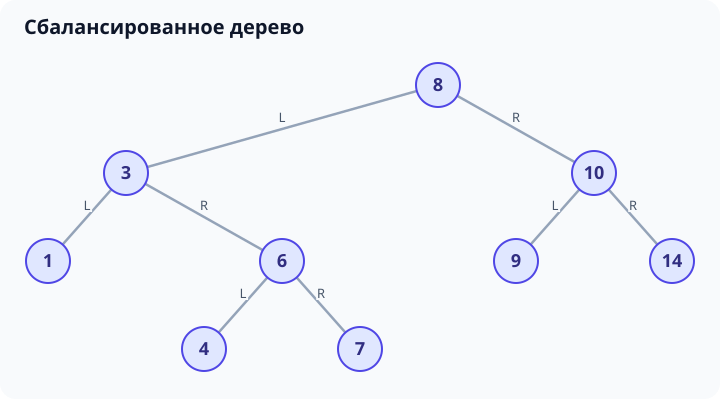

Результат проверки: **True**

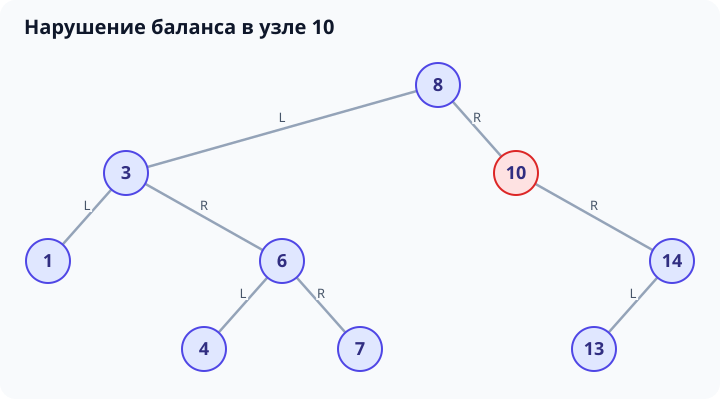

Результат проверки: **False**

In [3]:
balanced_tree = Node(
    8,
    left=Node(3, left=Node(1), right=Node(6, left=Node(4), right=Node(7))),
    right=Node(10, left=Node(9), right=Node(14)),
)

unbalanced_node = Node(10, right=Node(14, left=Node(13)))
unbalanced_tree = Node(
    8,
    left=Node(3, left=Node(1), right=Node(6, left=Node(4), right=Node(7))),
    right=unbalanced_node,
)

display(SVG(tree_svg(balanced_tree, "Сбалансированное дерево")))
display(Markdown(f"Результат проверки: **{is_balanced(balanced_tree)}**"))

display(SVG(tree_svg(unbalanced_tree, "Нарушение баланса в узле 10", unbalanced_node)))
display(Markdown(f"Результат проверки: **{is_balanced(unbalanced_tree)}**"))

**Пошаговая работа `is_balanced`.** Рассмотрим второе дерево.
Начинаем с `check_height(8)`. Функция сначала спускается к листьям,
а затем вычисляет высоты при возврате из рекурсии.

В таблице показан порядок возвратов для непустых узлов.
Вызовы для `None` возвращают `0` и отдельно не перечислены.

| Шаг | Узел | Результат слева | Результат справа | Возвращаемое значение |
|---|---:|---:|---:|---|
| 1 | 1 | 0 | 0 | `1` |
| 2 | 4 | 0 | 0 | `1` |
| 3 | 7 | 0 | 0 | `1` |
| 4 | 6 | 1 | 1 | `2` |
| 5 | 3 | 1 | 2 | `3` |
| 6 | 13 | 0 | 0 | `1` |
| 7 | 14 | 1 | 0 | `2` |
| 8 | 10 | 0 | 2 | `-1`, потому что разница равна `2` |
| 9 | 8 | 3 | -1 | `-1`, нарушение уже найдено справа |

Значение `-1` означает нарушение баланса, а не высоту поддерева.
Получив его от правого ребёнка, вызов для корня сразу возвращает `-1`.
Поэтому `is_balanced` возвращает `False`.

В первом дереве оба ребёнка узла `10` - листья. Он возвращает высоту `2`,
а корень получает высоты `3` и `2`. Разница допустима, корень возвращает
высоту `4`, и итоговый результат - `True`.

**Сложность**

Пусть `n` - число узлов, а `h` - высота дерева (глубина).

| Операция | Время | Память |
|---|---|---|
| Проверка непустого дерева | `O(n)` в худшем случае | `O(h)` для стека вызовов |
| Проверка пустого дерева | `O(1)` | `O(1)` |

Каждый узел посещается не больше одного раза. Для него выполняются
сравнение двух высот и вычисление максимума - это `O(1)` действий.
Если нарушение найдено раньше, часть дерева может остаться непроверенной,
но в худшем случае нужно посетить все `n` узлов.

Максимальное число одновременно активных вызовов пропорционально высоте
дерева. При сбалансированной форме дополнительная память составляет
`O(log n)`, у дерева-цепочки - `O(n)`. Само входное дерево в эту оценку
не включаем. Итоговый результат `True` или `False` занимает `O(1)` памяти.

Python ограничивает глубину рекурсии. Для теста с цепочками из 2500 узлов
лимит временно увеличивается до 6000 или сохраняется более высокий
исходный лимит. После теста исходное значение восстанавливается.

**Тесты**

In [4]:
import sys
import unittest
from copy import deepcopy
from functools import lru_cache


class TestBalancedBinaryTree(unittest.TestCase):
    def test_empty(self):
        self.assertIs(is_balanced(None), True)

    def test_single(self):
        for value in [0, -7, 42]:
            with self.subTest(value=value):
                self.assertIs(is_balanced(Node(value)), True)

    def test_one_child(self):
        self.assertIs(is_balanced(Node(2, left=Node(1))), True)
        self.assertIs(is_balanced(Node(2, right=Node(3))), True)

    def test_balanced_full(self):
        def build(levels):
            if levels == 0:
                return None
            return Node(levels, build(levels - 1), build(levels - 1))

        for levels in range(1, 10):
            with self.subTest(levels=levels):
                self.assertIs(is_balanced(build(levels)), True)

    def test_balanced_asymmetric(self):
        root = Node(
            8,
            Node(3, Node(1), Node(6, Node(4), Node(7))),
            Node(10, Node(9), Node(14)),
        )
        self.assertIs(is_balanced(root), True)

    def test_left_chain(self):
        root = Node(3, left=Node(2, left=Node(1)))
        self.assertIs(is_balanced(root), False)

    def test_right_chain(self):
        root = Node(1, right=Node(2, right=Node(3)))
        self.assertIs(is_balanced(root), False)

    def test_zigzag_chain(self):
        root = Node(3, left=Node(1, right=Node(2)))
        self.assertIs(is_balanced(root), False)

    def test_unbalanced_left_subtree(self):
        root = Node(
            8,
            Node(3, left=Node(2, left=Node(1))),
            Node(10, Node(9), Node(14)),
        )
        self.assertIs(is_balanced(root), False)

    def test_unbalanced_right_subtree(self):
        root = Node(
            8,
            Node(3, Node(1), Node(6)),
            Node(10, right=Node(12, right=Node(14))),
        )
        self.assertIs(is_balanced(root), False)

    def test_equal_root_heights(self):
        root = Node(
            8,
            Node(3, left=Node(2, left=Node(1))),
            Node(10, right=Node(12, right=Node(14))),
        )
        self.assertIs(is_balanced(root), False)

    def test_values_do_not_matter(self):
        trees = [
            Node(0, Node(100), Node(-100)),
            Node(5, Node(5), Node(5)),
            Node(0, Node(-(10 ** 400)), Node(10 ** 400)),
        ]
        for root in trees:
            with self.subTest(root=root):
                self.assertIs(is_balanced(root), True)

    def test_tree_unchanged(self):
        cases = [
            (Node(2, Node(1), Node(3)), True),
            (Node(3, left=Node(2, left=Node(1))), False),
        ]
        for root, expected in cases:
            before = deepcopy(root)
            self.assertIs(is_balanced(root), expected)
            self.assertIs(is_balanced(root), expected)
            self.assertEqual(root, before)

    def test_small_tree_shapes(self):
        @lru_cache(None)
        def shapes(size):
            if size == 0:
                return (None,)
            return tuple(
                (left, right)
                for left_size in range(size)
                for left in shapes(left_size)
                for right in shapes(size - 1 - left_size)
            )

        def build(shape):
            if shape is None:
                return None
            return Node(0, build(shape[0]), build(shape[1]))

        def height_by_levels(root):
            level = [] if root is None else [root]
            height = 0
            while level:
                height += 1
                level = [
                    child
                    for node in level
                    for child in (node.left, node.right)
                    if child is not None
                ]
            return height

        def expected_balance(root):
            stack = [root]
            while stack:
                node = stack.pop()
                if node is None:
                    continue
                if abs(height_by_levels(node.left) - height_by_levels(node.right)) > 1:
                    return False
                stack.extend([node.left, node.right])
            return True

        for size in range(7):
            for index, shape in enumerate(shapes(size)):
                with self.subTest(size=size, shape=index):
                    root = build(shape)
                    self.assertIs(is_balanced(root), expected_balance(root))

    def test_deep_trees(self):
        previous_limit = sys.getrecursionlimit()
        try:
            sys.setrecursionlimit(max(previous_limit, 6000))

            left_chain = Node(2499)
            current = left_chain
            for value in range(2498, -1, -1):
                current.left = Node(value)
                current = current.left
            self.assertIs(is_balanced(left_chain), False)

            right_chain = Node(0)
            current = right_chain
            for value in range(1, 2500):
                current.right = Node(value)
                current = current.right
            self.assertIs(is_balanced(right_chain), False)
        finally:
            sys.setrecursionlimit(previous_limit)

In [5]:
suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestBalancedBinaryTree)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), "Некоторые тесты завершились ошибкой"
print(f"Успешно пройдено тестов: {test_result.testsRun}")

test_balanced_asymmetric (__main__.TestBalancedBinaryTree.test_balanced_asymmetric) ... ok
test_balanced_full (__main__.TestBalancedBinaryTree.test_balanced_full) ... ok
test_deep_trees (__main__.TestBalancedBinaryTree.test_deep_trees) ... ok
test_empty (__main__.TestBalancedBinaryTree.test_empty) ... ok
test_equal_root_heights (__main__.TestBalancedBinaryTree.test_equal_root_heights) ... ok
test_left_chain (__main__.TestBalancedBinaryTree.test_left_chain) ... ok
test_one_child (__main__.TestBalancedBinaryTree.test_one_child) ... ok
test_right_chain (__main__.TestBalancedBinaryTree.test_right_chain) ... ok
test_single (__main__.TestBalancedBinaryTree.test_single) ... ok
test_small_tree_shapes (__main__.TestBalancedBinaryTree.test_small_tree_shapes) ... ok
test_tree_unchanged (__main__.TestBalancedBinaryTree.test_tree_unchanged) ... ok
test_unbalanced_left_subtree (__main__.TestBalancedBinaryTree.test_unbalanced_left_subtree) ... ok
test_unbalanced_right_subtree (__main__.TestBalancedBi

Успешно пройдено тестов: 15
